# <div align="center">TRABALHO DE ECAC</div>

## Trabalho realizado por:
- Luis Nogueira
- Alicia
- Sofia

# DATASET, DATA UNDERSTANDING AND EXPLATORY ANALYSIS

## The Dataset
Foi nos disponibilizada metadata de músicas. Esta continha linhas com informação incompleta (colunas não preenchidas) que, ao importármos toda a data, foram logo de seguida, separadas, tal como pedido no enunciado.

In [52]:
import pandas as pd 

df_metadata = pd.read_csv('metadata.csv')
df_test_keys = pd.read_csv('test_songs.csv')

is_test = df_metadata['Audio_Song'].isin(df_test_keys['Audio_Song'])

df_train_dev = df_metadata[~is_test].copy()
df_test = df_metadata[is_test].copy()

print(f"Conjunto de treino/desenvolvimento: {len(df_train_dev)} linhas")
print(f"Conjunto de teste isolado: {len(df_test)} linhas")


Conjunto de treino/desenvolvimento: 932 linhas
Conjunto de teste isolado: 416 linhas


932 linhas - Este é o tamanho do conjunto de formação e de desenvolvimento (df_train_dev). Aqui será realizada a análise exploratória, a limpeza de dados e o treino dos modelos.

416 linhas - corresponde ao tamanho do conjunto de teste isolado (df_test), que inclui 409 músicas de teste do MERGE e sete duplicados, ficando congelado até à avaliação final.

### Contagens e Tabela do split de dados

A partição de teste engloba as 409 músicas pertencentes ao split oficial de 31% do dataset MERGE. Devido à injeção deliberada de ruído no dataset (Defeito A1: 25 linhas duplicadas exatas em metadata.csv), o filtro resulta em 416 linhas no conjunto de teste.

<div style="text-align: center; display: flex; justify-content: center;">

| Conjunto de Dados | Variável | Total de Linhas | Músicas Únicas | Duplicados | Função no Projeto |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Treino & Dev** | `df_train_dev` | **932** | 914 | 18 | Limpeza, EDA e Treino com Validação Cruzada |
| **Teste Isolado** | `df_test` | **416** | 409 | 7 | Avaliação final congelada |
| **Total Global** | `df_metadata` | **1 348** | 1 323 | 25 | Total de registos em metadata.csv |

</div>


### Data Understanding

#### 2.1

Cada coluna contem um tipo de informação descritiva para cada música. As 27 colunas do ficheiro metadata.cvs dividem-se nas seguintes categorias funcionais:

**Indentifiers:** Chaves primarias e códigos de ligação aos ficheiros de audio, texto de letras e base de dados editorial. Nao tem valos preditivo numérico.

Audio_Song, Lyric_Song, AppearancesTrackIDs, AppearencesAlbumIDs

**Administrative:** Metadata de controlo de recolha de dados e links para pre-escuta de audio.

AllMusic Extraction Date, SamplURL

**Measurements and Descriptive:** Atributos quantitativos e numéricos

Duration, Relevance, Year, LowestYear, ActualYear, num_Genres, num_MoodsAll

**Content/Metadata Tags:** Rotulos editoriais textuais e respetivos do AllMusic sobre e conteudo, genero, estilo e clima da musica.

Song, Artist, Album, Genres, GenreWeights, Styles, StyleWeights, Themes, ThemeWeights, Moods, MoodsAll, MoodsAllWeights, Sample



**Target : Quadrant**

Q1, Q2, Q3, Q4 correspondentes aos quatro quadrantes do plano Valencia - Arousal.

#### 2.2

Não, as quatro fontes de dados nao se cruzam numa relação estrita de um-para-um. A quebra de relação ocorre:

Metadata to Audio and Lyrics:

Devido à presença de 25 linhas duplicadas exatas no metadat.csv (Defeito A1), a relação passa de 1:1 para N:1. Existem 1348 linhas em metada.csv para apenas 1323 musicas Audio_Song.

Metadata to Album Covers:

A relação quebra devido a falhas de cobertura para albuns sem capa disponivel e a ediçoes do mesmo album que partilham a mesma imagem.

O que decorre/resulta dessa quebra é a duplicação indesejada, Data Leakage e dados multimodais imcompleto.



#### 2.3

As lista de colunas suspeitas de Target Leakage são Moods, MoodsAll, MoodsAll, MoodsAllWeights, Theme e Styles. Estas colunas devem ser marcadas para remoção do conjunto de features preditivas, pois na aplicação real do modelo em novas faixas de audio/letra, estas tags manuais do AllMusic não estarão disponiveis.

### EXPLORATORY ANALYSIS

#### 3.1
O código abaixo tem um output que descreve a avaliação da distribuição da variavel alvo, na indentificação de padroes de valores em falta e na inspeção da amplitude das caracteristicas quantitativas.

In [53]:
import pandas as pd

# Percentagem de cada quadrante
percentagem = df_train_dev['Quadrant'].value_counts(normalize=True) * 100
contagem = df_train_dev['Quadrant'].value_counts()

# Juntar num único quadro
resumo_target = pd.DataFrame({
    'Total de Músicas': contagem,
    'Percentagem (%)': percentagem.round(2)
})

print("    Distribuição da Variável Alvo (Quadrant)    ")
print(resumo_target)

# Analise de valores em falta 
nulos_abs = df_train_dev.isnull().sum()
nulos_pct = (df_train_dev.isnull().sum() / len(df_train_dev)) * 100

resumo_nulos = pd.DataFrame({
    "Valores Nulos" : nulos_abs,
    "Percentagem": nulos_pct.round(2)
})

resumo_nulos = resumo_nulos[resumo_nulos["Valores Nulos"] > 0]

print("\n Colunas com Valores em Falta  ")
print(resumo_nulos)

cols_num = ['Duration', 'Relevance', 'Year', 'LowestYear', 'ActualYear', 'num_Genres', 'num_MoodsAll']

resumo_escala = df_train_dev[cols_num].agg(['min', 'max']).T

print("\n    Resumo Estatístico das Variáveis Numéricas    ")
print(resumo_escala.round(2))



    Distribuição da Variável Alvo (Quadrant)    
          Total de Músicas  Percentagem (%)
Quadrant                                   
Q1                     374            40.13
Q3                     356            38.20
Q2                     112            12.02
Q4                      90             9.66

 Colunas com Valores em Falta  
                     Valores Nulos  Percentagem
Relevance                      160        17.17
Year                           116        12.45
LowestYear                     322        34.55
Duration                       190        20.39
Moods                           73         7.83
MoodsAll                        21         2.25
MoodsAllWeights                 24         2.58
Genres                         126        13.52
GenreWeights                    22         2.36
Themes                         151        16.20
ThemeWeights                   151        16.20
Styles                          82         8.80
StyleWeights                  

#### 3.2

As colunas num_Genres e num_MoodsAll têm 98.93% dos dados não existentes. Outras colunas, como LowestYear (34,55 % de dados em falta) e ActualYear (22,75 % de dados em falta), também apresentam uma percentagem significativa de dados em falta, mas não estão tão vazias como as anteriores.

In [54]:
# Identificar colunas constantes

valores_unicos = df_train_dev.nunique(dropna=True)

colunas_constantes = valores_unicos[valores_unicos == 1]

print("Colunas Constantes ")
if colunas_constantes.empty:
    print("Não foram encontradas colunas constantes.")
else:
    for col in colunas_constantes.index:
        valor = df_train_dev[col].dropna().iloc[0]
        print(f"{col}: valor constante = {valor!r}")

# Investigar colunas com valores suspeitos
colunas_suspeitas = [
    'Duration',
    'Year',
    'LowestYear',
    'ActualYear',
    'num_Genres',
    'num_MoodsAll'
]

print("\n Investigação das Colunas Suspeitas ")

for col in colunas_suspeitas:
    if col in df_train_dev.columns:
        serie = df_train_dev[col]

        print(f"\n--- {col} ---")
        print("Tipo de dados:", serie.dtype)
        print("Valores únicos:", serie.nunique(dropna=True))
        print("Valores mais frequentes:")
        print(serie.value_counts(dropna=False).head(10))

        if pd.api.types.is_numeric_dtype(serie):
            print("Mínimo:", serie.min())
            print("Máximo:", serie.max())


Colunas Constantes 
Não foram encontradas colunas constantes.

 Investigação das Colunas Suspeitas 

--- Duration ---
Tipo de dados: float64
Valores únicos: 272
Valores mais frequentes:
Duration
 NaN      190
 0.0       61
-1.0       21
 183.0     10
 189.0      8
 157.0      7
 159.0      7
 149.0      7
 171.0      7
 200.0      7
Name: count, dtype: int64
Mínimo: -1.0
Máximo: 367000.0

--- Year ---
Tipo de dados: str
Valores únicos: 487
Valores mais frequentes:
Year
NaN           116
1983-??-??     10
1997-??-??      8
1958-??-??      8
1989-??-??      8
1991-??-??      8
1980-??-??      7
1992-??-??      7
1963-??-??      7
1986-??-??      6
Name: count, dtype: int64

--- LowestYear ---
Tipo de dados: str
Valores únicos: 371
Valores mais frequentes:
LowestYear
NaN           322
1994-??-??      8
1993-??-??      7
1986-??-??      7
1983-??-??      7
1992-??-??      7
1984-??-??      7
1963-??-??      7
1989-??-??      7
1997-??-??      6
Name: count, dtype: int64

--- ActualYear ---

Nenhuma das variáveis apresenta apenas um único valor distinto entre os seus valores não nulos. Assim, todas as colunas apresentam alguma variabilidade.

Relativamente às colunas que podem mesurar algo diferente do que dizem, Duration apresenta valores como -1 e 0, bem como um máximo de 367000, o que justifica investigar possíveis valores inválidos ou diferenças de unidades. As colunas Year e LowestYear contêm datas incompletas, em vez de anos numéricos simples. Por sua vez, ActualYear apresenta valores compatíveis com anos. Estas observações levantam dúvidas sobre a interpretação e o formato de algumas variáveis.

#### 3.3

Para mostrar o quão bem cada coluna consegue prever o quadrant, escolhemos verificar a associação de forma visual através da análise de gráficos.

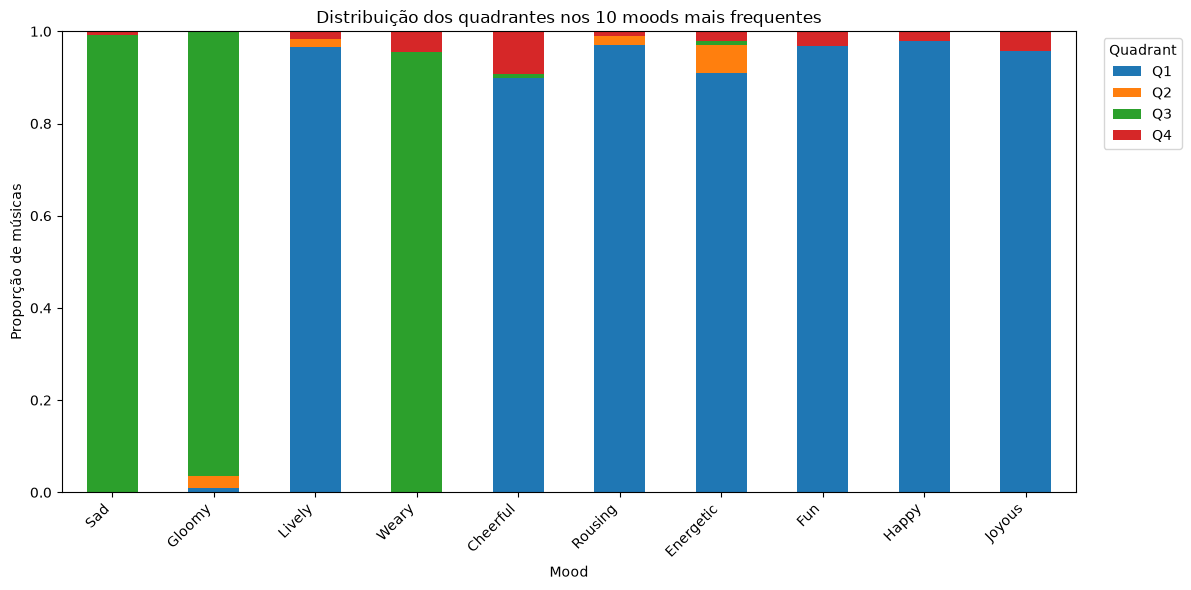

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# SECÇÃO 3.3 — MOODS E QUADRANT
# ============================================================

# Selecionar as colunas necessárias
dados_moods = df_train_dev[['Quadrant', 'Moods']].dropna().copy()

# Separar os moods quando existem vários na mesma célula
dados_moods['Moods'] = dados_moods['Moods'].astype(str).str.split(r'[,;|]')

dados_moods = dados_moods.explode('Moods').reset_index(drop=True)
dados_moods['Moods'] = dados_moods['Moods'].str.strip()

# Remover categorias vazias
dados_moods = dados_moods[dados_moods['Moods'] != '']

# Selecionar os 10 moods mais frequentes
top_moods = dados_moods['Moods'].value_counts().head(10).index

dados_moods = dados_moods[dados_moods['Moods'].isin(top_moods)]

# Calcular a proporção de cada quadrante dentro de cada mood
proporcoes = pd.crosstab(
    dados_moods['Moods'],
    dados_moods['Quadrant'],
    normalize='index'
)

# Ordenar os moods pelo número de ocorrências
ordem_moods = dados_moods['Moods'].value_counts().index
proporcoes = proporcoes.reindex(ordem_moods)

proporcoes.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Distribuição dos quadrantes nos 10 moods mais frequentes')
plt.xlabel('Mood')
plt.ylabel('Proporção de músicas')
plt.legend(title='Quadrant', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

O gráfico de Barras Empilhadas usando variáveis categóricas, permitem visualizar a proporção dos quadrantes dentro de cada categoria. Uma categoria dominada por um único quadrante revela uma forte associação, ajudando a perceber se a variável partilha a mesma origem conceptual que o alvo. Obviamente, que neste caso a associação entre a Mood e o Quadrante Emocional vai ser elevada pois a coluna avaliada deriva diretamente dos eixos originais que definem os quadrantes, havendo assim data leakage.

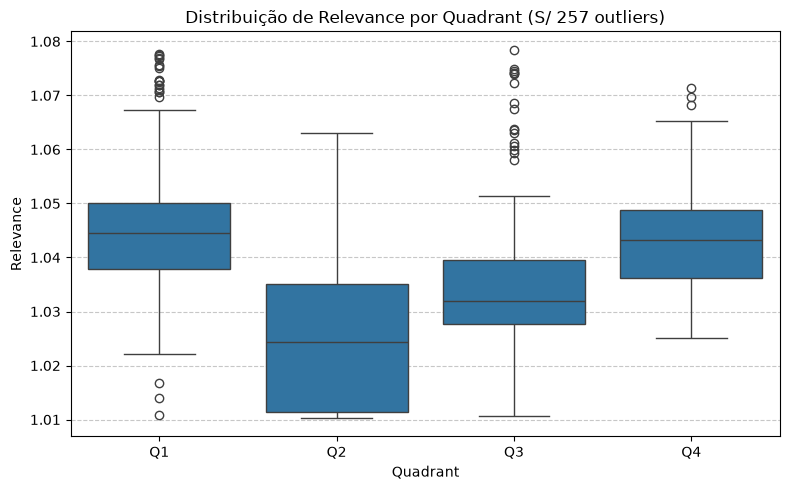

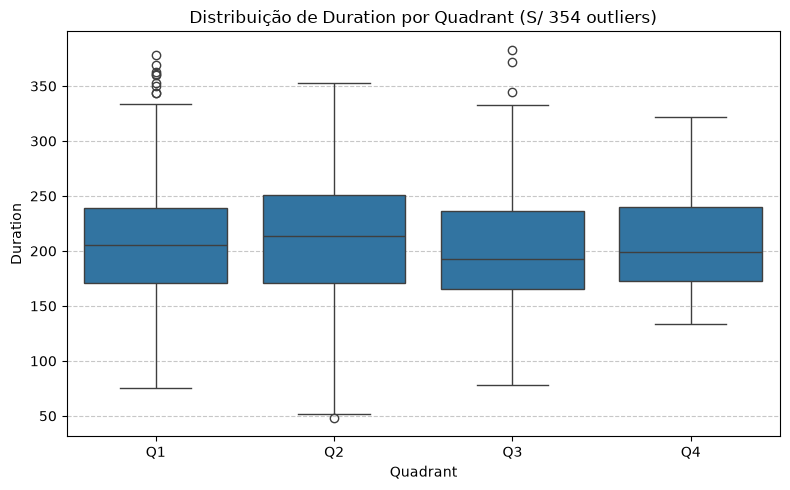

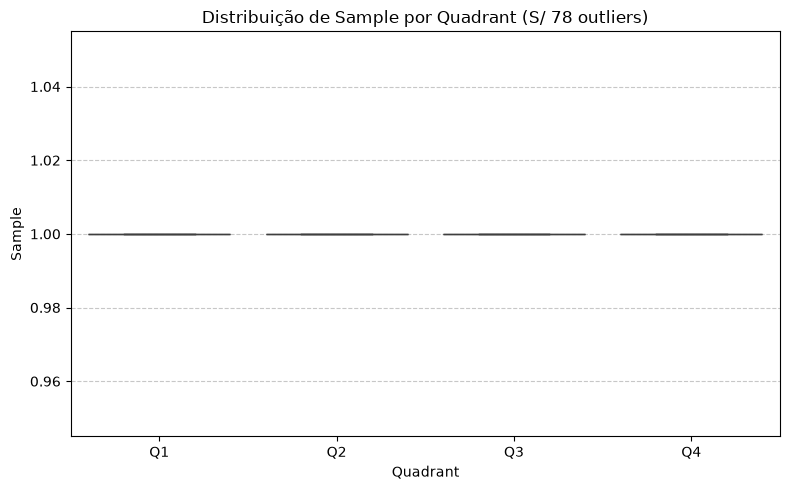

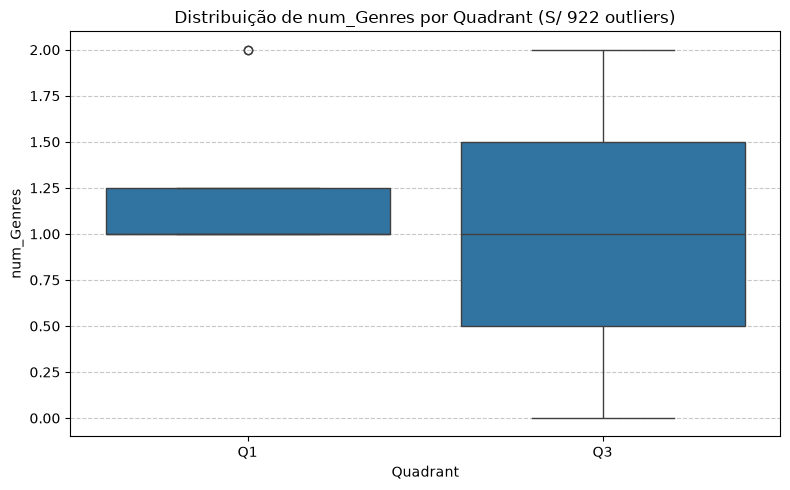

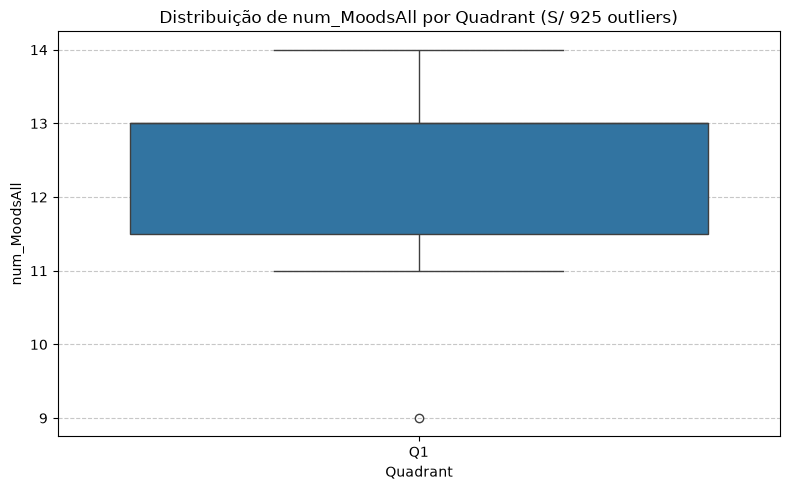

In [56]:
# ============================================================
# SECÇÃO 3.3 — ASSOCIAÇÃO DE VARIÁVEIS NUMÉRICAS (BOXPLOTS)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

def filtrar_outliers_iqr(df, coluna):
    """Filtra os outliers de uma coluna usando o método IQR (Tukey's Fences)."""
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Mantém apenas os valores dentro dos limites
    return df[(df[coluna] >= limite_inferior) & (df[coluna] <= limite_superior)].copy()

# ============================================================
# GERAR OS GRÁFICOS SEM OUTLIERS
# ============================================================

dados_num = df_train_dev.dropna(subset=['Quadrant']).copy()
colunas_numericas = dados_num.select_dtypes(include=['number']).columns
ordem_quadrantes = ['Q1', 'Q2', 'Q3', 'Q4']

for coluna in colunas_numericas:
    # Criar um dataframe temporário só com os dados normais para esta coluna
    dados_limpos = filtrar_outliers_iqr(dados_num, coluna)

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=dados_limpos,
        x='Quadrant',
        y=coluna,
        order=[q for q in ordem_quadrantes if q in dados_limpos['Quadrant'].unique()]
    )

    # Calcular quantos registos foram escondidos para colocares no título
    removidos = len(dados_num) - len(dados_limpos)

    plt.title(f'Distribuição de {coluna} por Quadrant (S/ {removidos} outliers)')
    plt.xlabel('Quadrant')
    plt.ylabel(coluna)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

Para avaliar a capacidade preditiva das variáveis numéricas contínuas, utilizámos Boxplots (com os outliers filtrados), que permitem visualizar facilmente o grau de sobreposição das distribuições de dados entre os quatro quadrantes emocionais para responder às exigências da exploração de dados. Foi possível chegar a algumas conclusões:
- Falta de utilidade (Sample): A representação desta coluna resume-se a uma linha horizontal constante no valor 1.0. Sem qualquer variação, é impossível usá-la para distinguir as classes, tornando-a inútil para prever o alvo.
- Fraco poder preditivo isolado: Variáveis como Duration, Relevance e o número de Moods/Genres apresentam uma enorme sobreposição das caixas e medianas entre todos os quadrantes. Isto significa que, isoladamente, não conseguem prever a emoção de uma música com precisão.
- Ausência de fuga Data Leakage: Como nenhuma destas variáveis numéricas separa os quadrantes na perfeição, confirmamos que não sofrem de fugas de informação, sendo atributos perfeitamente legítimos para o modelo.

#### 3.4
Na secção 2.3, através da leitura da documentação e compreensão do problema, identificámos teoricamente as seguintes colunas como suspeitas de originarem fuga de informação (target leakage): Moods, MoodsAll, MoodsAllWeights, Theme e Styles. A justificação baseou-se no facto de serem etiquetas manuais do AllMusic, que não estariam disponíveis na aplicação real do modelo, e de a documentação revelar que estas mesmas etiquetas foram utilizadas para mapear os eixos de valência e arousal que definem o quadrante.

A análise exploratória empírica realizada na secção 3.3 confirmou integralmente estas suspeitas. Através da visualização em gráficos de barras empilhadas, confirmámos que colunas como Moods preveem o alvo com precisão quase absoluta, confirmando o data leakage.

Todas as colunas problemáticas de metadados que o código sinalizou por preverem o alvo 'demasiado bem' no passo 3.3 já tinham sido detetadas e corretamente marcadas para remoção no passo 2.3.

#### 3.5

In [57]:
df_completo = pd.concat([df_train_dev, df_test])

# 1. Quantas músicas tem cada artista?
musicas_por_artista = df_completo['Artist'].value_counts()

print("Músicas por artista (Top 10):")
print(musicas_por_artista.head(10))

print(f"\nMédia de músicas por artista: {musicas_por_artista.mean():.2f}")
print(f"Número de artistas com apenas 1 música: {(musicas_por_artista == 1).sum()}")

# 2. Quantas músicas de teste partilham um artista com o resto dos dados?
artistas_treino = set(df_train_dev['Artist'].dropna().unique())
artistas_teste = set(df_test['Artist'].dropna().unique())

# Encontrar a interseção (artistas presentes em ambos os conjuntos)
artistas_partilhados = artistas_treino.intersection(artistas_teste)

# Contar quantas músicas no df_test pertencem a estes artistas partilhados
musicas_teste_partilhadas = df_test[df_test['Artist'].isin(artistas_partilhados)].shape[0]
total_musicas_teste = df_test.shape[0]

print(f"\nMúsicas no teste que partilham artista com o treino: {musicas_teste_partilhadas} (de um total de {total_musicas_teste})")

Músicas por artista (Top 10):
Artist
Billie Holiday       22
Ella Fitzgerald      14
The Beatles          13
Elvis Presley        13
Madonna              12
Jimmy  Reed          11
Al Green             11
Megadeth             11
Slayer               10
Lightnin' Hopkins    10
Name: count, dtype: int64

Média de músicas por artista: 1.61
Número de artistas com apenas 1 música: 627

Músicas no teste que partilham artista com o treino: 204 (de um total de 416)


No que diz respeito à separação dos dados, identificou-se que  músicas do conjunto de teste (num total de 409) pertencem a artistas que também estão presentes no resto dos dados de treino/validação. Esta elevada partilha de artistas entre os dois conjuntos depara-se com as exigências da avaliação do modelo, um aspeto que será determinante para a escolha do esquema de cross-validation na Secção 8.